# D1ECD – Estatística para Ciência de Dados
## Atividade Avaliativa 01 – Estatística Descritiva e Média Móvel

**Nome:** Rodrigo Gimenes Rodrigues  
**Matrícula:** CP3071782  
**Curso:** Especialização em Ciência de Dados  
**Período/Ano:** 2026/2  
**Campus:** Campinas  
**Turno:** EAD  
**Professor:** Kakimoto


## Conjunto de dados

Código fornecido no enunciado para gerar a série de 60 dias.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fixa a semente aleatória para reprodutibilidade dos resultados
np.random.seed(42)

dias = pd.date_range(start='2026-01-01', periods=60, freq='D')
tendencia = np.linspace(50, 110, 60)
sazonalidade = 15 * np.sin(np.linspace(0, 4 * np.pi, 60))
ruido = np.random.normal(loc=0, scale=8, size=60)
transacoes = tendencia + sazonalidade + ruido

df = pd.DataFrame({
    'Data': dias,
    'Transacoes_Milhares': np.round(transacoes, 2)
})

serie = df['Transacoes_Milhares']
df.head()

,Data,Transacoes_Milhares
0,2026-01-01,53.97
1,2026-01-02,53.08
2,2026-01-03,63.41
3,2026-01-04,74.18
4,2026-01-05,63.48


## Parte 1 – Estatística descritiva e medidas de tendência central


In [2]:
media = serie.mean()
mediana = serie.median()
moda = serie.mode()
minimo = serie.min()
maximo = serie.max()
medio_alcance = (minimo + maximo) / 2

print('Média:', round(media, 2))
print('Mediana:', round(mediana, 2))
print('Moda:', moda.tolist() if serie.value_counts().max() > 1 else 'não há moda (todos os valores são únicos)')
print('Mínimo:', minimo)
print('Máximo:', maximo)
print('Médio alcance:', round(medio_alcance, 2))
print('Média - mediana:', round(media - mediana, 2))

Média: 78.76
Mediana: 77.9
Moda: não há moda (todos os valores são únicos)
Mínimo: 46.23
Máximo: 117.8
Médio alcance: 82.02
Média - mediana: 0.86


### Comentário – Parte 1

Rodando o código, a média deu 78,76 e a mediana 77,91. São valores bem próximos. A média um pouco maior que a mediana sugere uma leve assimetria positiva, mas nada muito forte.

Sobre a moda: não tem. Cada dia deu um valor diferente, então a série é amodal.

O médio alcance ficou em 82,02 ((46,23 + 117,80) / 2). Esse número usa só o menor e o maior valor, então acaba sendo puxado pelos extremos. Aqui o máximo é o último dia da série, que já vem de uma tendência de alta, e o mínimo parece um vale. Por isso o médio alcance não representa bem o centro desses dados. Média e mediana fazem mais sentido.


## Parte 2 – Variabilidade e dispersão


In [3]:
variancia = serie.var(ddof=1)
desvio = serie.std(ddof=1)
q1 = serie.quantile(0.25)
q2 = serie.quantile(0.50)
q3 = serie.quantile(0.75)
iqr = q3 - q1
cv = (desvio / media) * 100

limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr
outliers = df[(serie < limite_inf) | (serie > limite_sup)]

print('Variância amostral:', round(variancia, 2))
print('Desvio padrão:', round(desvio, 2))
print('Q1:', round(q1, 2))
print('Q2:', round(q2, 2))
print('Q3:', round(q3, 2))
print('IQR:', round(iqr, 2))
print('CV (%):', round(cv, 2))
print('Limite inferior:', round(limite_inf, 2))
print('Limite superior:', round(limite_sup, 2))
print('Qtd de outliers:', len(outliers))
print(outliers if len(outliers) else 'Nenhum outlier encontrado.')

Variância amostral: 341.98
Desvio padrão: 18.49
Q1: 63.46
Q2: 77.9
Q3: 93.05
IQR: 29.59
CV (%): 23.48
Limite inferior: 19.08
Limite superior: 137.43
Qtd de outliers: 0
Nenhum outlier encontrado.


### Comentário – Parte 2

A variância amostral deu 341,98 e o desvio padrão 18,49. Ou seja, os dias costumam variar cerca de 18,5 mil transações em relação à média.

Os percentis ficaram: Q1 = 63,46, Q2 = 77,91 e Q3 = 93,05. O IQR foi 29,59, então a metade central dos dias está entre esses valores.

O CV deu 23,48%. Dá para dizer que a dispersão relativa é moderada. Vale lembrar que a série tem tendência de crescimento e sazonalidade, então parte dessa variação não é só “ruído do dia a dia”.

Usando o critério do boxplot (1,5 × IQR), os limites foram 19,08 e 137,43. Nenhum ponto ficou fora, então não apareceu outlier.


## Parte 3 – Média móvel

Foram calculadas duas médias móveis simples: janela de 7 dias e janela de 14 dias.


In [4]:
def media_movel(dados, janela):
    valores = list(dados)
    resultado = [np.nan] * (janela - 1)
    for i in range(len(valores) - janela + 1):
        resultado.append(sum(valores[i:i+janela]) / janela)
    return resultado

df['MM7'] = media_movel(serie, 7)
df['MM14'] = media_movel(serie, 14)

print(df[['Data', 'Transacoes_Milhares', 'MM7', 'MM14']].tail(10))
print('MM7 no último dia:', round(df['MM7'].iloc[-1], 2))
print('MM14 no último dia:', round(df['MM14'].iloc[-1], 2))

         Data  Transacoes_Milhares         MM7       MM14
50 2026-02-20                89.33   87.155714  92.810000
51 2026-02-21                83.92   87.184286  92.594286
52 2026-02-22                82.51   86.454286  91.874286
53 2026-02-23                94.43   87.425714  91.138571
54 2026-02-24               100.04   87.722857  90.542857
55 2026-02-25               102.09   89.332857  90.503571
56 2026-02-26                91.29   91.944286  89.974286
57 2026-02-27                99.29   93.367143  90.261429
58 2026-02-28               108.46   96.872857  92.028571
59 2026-03-01               117.80  101.914286  94.184286
MM7 no último dia: 101.91
MM14 no último dia: 94.18


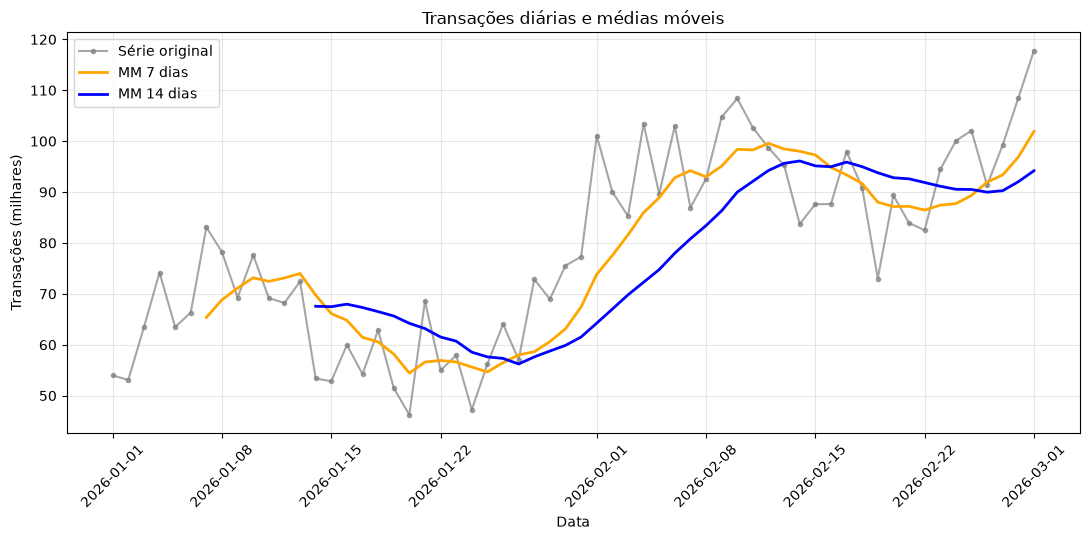

In [5]:
plt.figure(figsize=(11, 5.5))
plt.plot(df['Data'], df['Transacoes_Milhares'], color='gray', marker='o', markersize=3, alpha=0.7, label='Série original')
plt.plot(df['Data'], df['MM7'], color='orange', linewidth=2, label='MM 7 dias')
plt.plot(df['Data'], df['MM14'], color='blue', linewidth=2, label='MM 14 dias')
plt.title('Transações diárias e médias móveis')
plt.xlabel('Data')
plt.ylabel('Transações (milhares)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Comentário – Parte 3

No gráfico dá para ver bem a diferença entre as duas janelas. A de 7 dias acompanha mais de perto a série original: suaviza um pouco, mas ainda reage aos altos e baixos. No último dia ela ficou em 101,91.

A de 14 dias fica mais “lisa”. Ela mostra melhor a tendência geral, mas demora mais para acompanhar as mudanças. No final ficou em 94,18, abaixo da MM7, porque ainda carrega valores das semanas anteriores, que eram menores.

Resumindo: janela maior = mais suavização, mas também mais atraso.


## Parte 4 – Análise crítica e parecer de negócio

Olhando os 60 dias, a tendência geral é de crescimento. A série começa em 53,97 mil transações e termina em 117,80. A média dos 10 primeiros dias fica em 68,26 e sobe para 96,92 nos 10 últimos. Mesmo com oscilações e um vale mais baixo no meio (46,23 em 20/01), o volume no final do período é bem maior do que no começo. Para a fintech, isso significa mais carga na plataforma e, na prática, mais atenção com capacidade e infraestrutura.

Para o painel do time de infraestrutura, eu usaria a média móvel de 7 dias como principal. Ela suaviza o ruído do dia a dia e ainda reage rápido o suficiente quando a demanda muda. A de 14 dias pode ficar como apoio, mais para ver a tendência, mas sozinha ela atrasa demais e pode esconder um pico recente.

Sobre as medidas da Parte 1: os picos e a tendência de alta puxam a média um pouco acima da mediana (78,76 contra 77,91). Aqui a diferença é pequena, mas já mostra que a média sente mais os valores altos. O médio alcance sofre ainda mais, porque depende só do mínimo e do máximo. Então, para acompanhar a operação, faz mais sentido olhar a média móvel recente do que só a média geral dos 60 dias.
